# Train on $D^2_{min}$

For earlier attempts, we trained rearrangement as a binary classification
problem; either particles rearrange, or they don't. We used a cutoff in
$D^2_{min}$ to determine if particles rearranged. This approach worked, but it
had some quirks. 

In [2]:
import torch
from torch.utils.data import DataLoader, Dataset
from torch import nn
from sklearn.preprocessing import StandardScaler


import numpy as np
import polars as pl
import pandas as pd
import gsd.hoomd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud import ml
# from tqdm import tqdm

import glob
import os
import pathlib
import pickle
import signac
import freud
from numba import njit

from dataclasses import dataclass
from collections import defaultdict

import matplotlib.pyplot as plt
from scipy import stats
from typing import Union

# from dataset import GlassDataset
from model import AutoEncoder, LongAutoEncoder
from tqdm.notebook import tqdm

In [3]:
from monk import workflow, utils

In [4]:
cwd = pathlib.Path(os.getcwd())
parent = cwd.parent.parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())
local = cwd / "config.yaml"
local_config = workflow.get_any_yaml(local.as_posix())
DATA = local_config["data"]
PROJECT: signac.Project = signac.get_project(root=config['root'])
parent, config, local_config

(PosixPath('/home/ian/Projects/work/monk/workflows/2d-osc-shear/config.yaml'),
 {'root': '/media/ian/Data2/monk/2d-osc-shear',
  'origin': '/media/ian/Data2/monk/2d-esl'},
 {'data': '/media/ian/Poppy/improved-nn/d2min-v1'})

In [5]:
PROJECT.find_job_ids()

/tmp/ipykernel_1710194/2594364462.py:1: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  PROJECT.find_job_ids()


['634e14bc75836df75158fb15f379d8bb',
 '7ec2f6aca035e69077eab24383a21cb6',
 'cfa1e4c0007fd65d020f809715a6f0b4',
 'ecce68c50e28a33684826f28780bf6e9',
 '1d0fe2ba44a6f635f5504dcbcee0ebc9',
 '1083a2a09eec2c6cf215ebc7a9706cac',
 '09d3dccc56f1fa9330b57901cd232ab7',
 '6976a7c10ada4159010403f8027f3ea5',
 '9158e73b2e4c9fd1a565e1e5d1bc3af5',
 'c6d7afd0de62bfa16d05da47815227eb',
 'bf92a185d043ce3ef666e05e427c7e76',
 'a8f2c249ed85533b56b0729b7ab96d18']

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [7]:
val_data = ["1083a2a09eec2c6cf215ebc7a9706cac", "bf92a185d043ce3ef666e05e427c7e76"]
test_data = ["6976a7c10ada4159010403f8027f3ea5", "a8f2c249ed85533b56b0729b7ab96d18"]

In [8]:
# test HTL = 6976a7c10ada4159010403f8027f3ea5
# test ESL = a8f2c249ed85533b56b0729b7ab96d18
# val HTL = 1083a2a09eec2c6cf215ebc7a9706cac
# val ESL = bf92a185d043ce3ef666e05e427c7e76
# rest are training set

In [118]:
def get_desciptor(file):
    frame = int(utils.extract_between(file, "frame-", ".parquet"))
    cycle = (frame + 1)/40
    max_shear = float(utils.extract_between(file, "shear-", "_period"))
    period = float(utils.extract_between(file, "period-", "_temp"))
    temp = float(utils.extract_between(file, "temp-", "_frame"))
    return {"frame": frame, "cycle": cycle, "max_shear": max_shear, "period": period, "temp": temp}

def get_prep(file, jobs):
    id = file.split("/")[-2]
    return jobs[id].sp["prep"]

class GlassDataset(Dataset):
    def __init__(self, path = None, glob="*", mode="train", filter=None):
        if path is None:
            path = DATA

        path = pathlib.Path(path)
        job_ids = list(PROJECT.find_job_ids())

        if mode == "train":
            job_ids = [id for id in job_ids if id not in val_data + test_data]
        elif mode == "val":
            job_ids = val_data
        elif mode == "test":
            job_ids = test_data
        elif mode in job_ids:
            job_ids = [mode]
        else:
            raise ValueError(f"mode {mode} not recognized")
        
        self._jobs = {id: PROJECT.open_job(id=id) for id in job_ids}
        self._path = path.resolve()
        files = []
        descs = []
        for id in job_ids:
            files += list((self._path / id).glob(glob))
            descs += [get_desciptor(file.as_posix()) for file in files]

        if filter is not None:
            pair = [(file, desc) for file, desc in zip(files, descs) if filter(desc)]
            files, descs = zip(*pair)
        self._files = files
        self._desc = descs
        for file, desc in zip(self._files, self._desc):
            id = file.as_posix().split("/")[-2]
            desc["prep"] = get_prep(file.as_posix(), self._jobs)
            desc["id"] = id
        self._len = len(self._files)

    def __len__(self):
        return self._len
    
    def get_info(self, idx):
        file = self._files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        return data, desc
    
    def __getitem__(self, idx):
        file = self._files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        sfs = np.vstack(data["sfs"].to_numpy())

        shape = sfs.shape
        X = np.zeros((shape[0], shape[1] + 3), dtype=np.float32)
        # strain = data["strain"].to_numpy()
        X[:, 0] = desc["max_shear"]
        X[:, 1] = desc["temp"]
        X[:, 2] = data["soft"].to_numpy()
        X[:, 3:] = sfs
        tX = torch.tensor(X, dtype=torch.float32)#.to(device)
        d2min = np.log(data["d2min_irr"].to_numpy())
        ty = torch.tensor(d2min, dtype=torch.float32)#.to(device)
        return ty, tX

class SimpleCustomBatch:
    def __init__(self, data):
        transposed_data = list(zip(*data))
        self.y = torch.stack(transposed_data[0], 0).view(-1, 1)
        self.X = torch.stack(transposed_data[1], 0).view(-1, 57)

    # custom memory pinning method on custom type
    def pin_memory(self):
        self.y = self.y.pin_memory()
        self.X = self.X.pin_memory()
        return self

def collate_wrapper(batch):
    return SimpleCustomBatch(batch)

In [119]:
model = None

In [120]:
filter = lambda x: (x["max_shear"] == 0.03 and x["temp"] <= 1e-2)
dataset = GlassDataset(path=DATA, glob="*", mode="train", filter=filter)
test_dataset = GlassDataset(path=DATA, glob="*", mode="test", filter=filter)

/tmp/ipykernel_1710194/3848940409.py:19: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  job_ids = list(PROJECT.find_job_ids())


In [121]:
len(dataset), len(test_dataset)

(144, 36)

In [122]:
df, desc = dataset.get_info(2)
desc

{'frame': 679,
 'cycle': 17.0,
 'max_shear': 0.03,
 'period': 1000.0,
 'temp': 0.0019836,
 'prep': 'HTL',
 'id': '634e14bc75836df75158fb15f379d8bb'}

In [123]:
for i in range(20):
    _, desc = dataset.get_info(i)
    print(desc)

{'frame': 439, 'cycle': 11.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 599, 'cycle': 15.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 679, 'cycle': 17.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 399, 'cycle': 10.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 319, 'cycle': 8.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 719, 'cycle': 18.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 79, 'cycle': 2.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'

In [124]:
df.head()

,frame,strain,id,soft,sfs,soft_rev,sfs_rev,d2min_rev,d2min_left,d2min_right,d2min_irr
0,679,0.03,1,-0.045742,"[0.0, 0.0, 0.0, 0.0, 0.0714228, 0.0, 0.7385138...",-0.172028,"[0.0, 0.0, 0.0, 0.0, 0.072847754, 0.0, 0.74865...",0.068391,0.035099,0.006894,0.000045
1,679,0.03,0,0.061828,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.07789995, 0.0, 0.7...",0.122465,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.08542941, 0.0, 0.7...",0.061261,0.005975,0.044376,0.000037
2,679,0.03,1,-0.719232,"[0.0, 0.0, 0.0, 0.0, 0.07585772, 0.0, 0.760024...",-0.702984,"[0.0, 0.0, 0.0, 0.0, 0.093508765, 0.0, 0.86401...",0.105766,0.003471,0.095375,0.000033
3,679,0.03,0,-0.597455,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.023368418, 0.0, 0....",-0.703622,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.020229096, 0.0, 0....",0.031853,0.016651,0.006076,0.000157
4,679,0.03,0,0.019934,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.063...",-0.139615,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.037...",0.177016,0.007928,0.132552,0.000056


In [125]:
loader = DataLoader(dataset, batch_size=1, shuffle=True, pin_memory=True, collate_fn=collate_wrapper, num_workers=6)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=True, pin_memory=True, collate_fn=collate_wrapper, num_workers=6)

In [126]:
y_scaler = StandardScaler()
X_scaler = StandardScaler()

for idx, sample in enumerate(loader):
    y_scaler.partial_fit(sample.y.numpy())
    X_scaler.partial_fit(sample.X.numpy())
    # if idx == 100:
    #     break

In [127]:
if model is not None:
    del model

import gc         # garbage collect library
gc.collect()
torch.cuda.empty_cache() 

In [128]:
model = LongAutoEncoder(input_dim=54, add_dim=3, h_dim=200, z_dim=10, act=nn.LeakyReLU(), out_act=None).to(device)

loss = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

In [129]:
postfix = dict(epoch=0, loss=np.nan)
pbar = tqdm(total=len(loader), postfix=postfix)

losses = []
test_losses = []

# idx = 0
for epoch in range(10):
    postfix["epoch"] = epoch + 1
    for sample in loader:
        sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
        sample.X[:] = torch.asarray(X_scaler.transform(sample.X.numpy()))
        y = sample.y.to(device)
        X = sample.X.to(device)
        
        optimizer.zero_grad()

        y_hat, z = model(X)

        l = loss(y, y_hat)

        l.backward()

        optimizer.step()

        v = l.item()

        losses.append(v)

        pbar.update(1)
        postfix["loss"] = v
        pbar.set_postfix(postfix)
    
    pbar.reset()

    epoch_tloss = []

    for sample in test_loader:
        sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
        sample.X[:] = torch.asarray(X_scaler.transform(sample.X.numpy()))
        y = sample.y.to(device)
        X = sample.X.to(device)
        y_hat, z = model(X)
        l = loss(y, y_hat)
        v = l.item()
        epoch_tloss.append(v)
    tloss = np.mean(epoch_tloss)
    test_losses.append(tloss)
    postfix["test_loss"] = tloss
    pbar.set_postfix(postfix)
        

  0%|          | 0/144 [00:00<?, ?it/s, epoch=0, loss=nan]

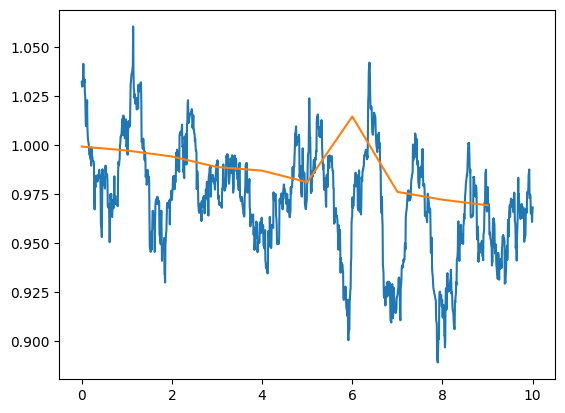

In [130]:
# import windowed average
from scipy.ndimage import uniform_filter1d

plt.plot(np.linspace(0, len(losses)/144, len(losses)), uniform_filter1d(losses, 100))
plt.plot(test_losses)

(array([1.000e+00, 6.000e+00, 1.000e+01, 1.400e+01, 2.200e+01, 2.600e+01,
        5.200e+01, 6.700e+01, 9.800e+01, 1.280e+02, 1.920e+02, 2.660e+02,
        3.350e+02, 4.480e+02, 5.170e+02, 6.440e+02, 8.060e+02, 8.950e+02,
        1.043e+03, 1.138e+03, 1.244e+03, 1.338e+03, 1.428e+03, 1.497e+03,
        1.498e+03, 1.545e+03, 1.489e+03, 1.526e+03, 1.454e+03, 1.415e+03,
        1.332e+03, 1.219e+03, 9.100e+02, 5.860e+02, 4.470e+02, 3.470e+02,
        2.300e+02, 2.040e+02, 1.720e+02, 1.650e+02, 1.790e+02, 1.960e+02,
        2.290e+02, 2.600e+02, 2.290e+02, 2.580e+02, 2.350e+02, 1.860e+02,
        1.500e+02, 1.310e+02, 1.240e+02, 1.260e+02, 1.580e+02, 1.920e+02,
        2.230e+02, 2.790e+02, 2.660e+02, 2.320e+02, 2.570e+02, 2.190e+02,
        2.260e+02, 1.830e+02, 1.910e+02, 2.000e+02, 1.570e+02, 1.090e+02,
        1.240e+02, 1.210e+02, 9.500e+01, 8.300e+01, 6.600e+01, 4.900e+01,
        3.800e+01, 4.800e+01, 2.600e+01, 3.100e+01, 2.300e+01, 2.100e+01,
        2.100e+01, 1.200e+01, 6.000e+0

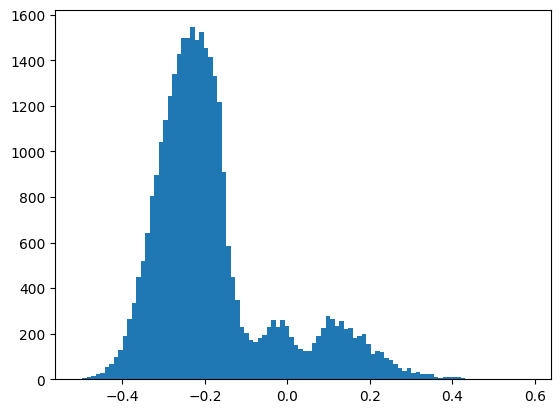

In [140]:
plt.hist(y.detach().cpu().numpy(), bins=100)
# np.xscale('log')

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-1.71373641, -1.6113608 , -1.50898518, -1.40660956, -1.30423394,
        -1.20185832, -1.0994827 , -0.99710708, -0.89473146, -0.79235584,
        -0.68998022, -0.5876046 , -0.48522898, -0.38285336, -0.28047774,
        -0.17810212, -0.0757265 ,  0.02664912,  0.12902473,  0.23140035,
         0.33377597,  0.43615159,  0.53852721,  0.64090283,  0.74327845,
         0.84565407,  0.94802969,  1.05040531,  1.15278093,  1.25515655,
         1.35753217,  1.45990779,  1.56228341,  1.66465903,  1.76703465,
         1.86941026,  1.97178588,  2.0741615 ,  2.17653712,  2.27891274,
         2.38128836,  2.48366398,  2.5860396 ,  2.68841522,  2.79079084,
         2.89316646,  2.99554208,  3.0979177 ,  3.20029332,  3.30266894,
         3.40504456])

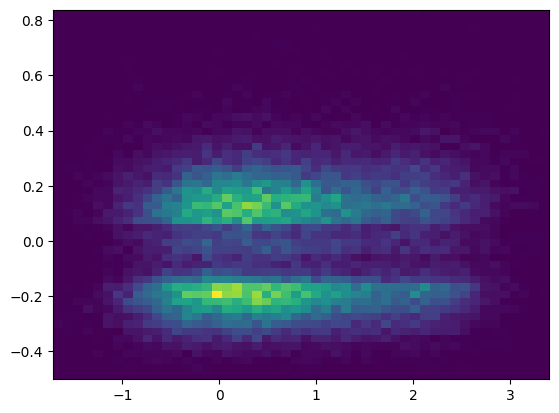

In [132]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_hat.detach().cpu().numpy().ravel(), bins=50)

In [133]:
y.detach().cpu().numpy()

array([[0.77801275],
       [1.4017998 ],
       [2.1508458 ],
       ...,
       [2.33074   ],
       [0.3033237 ],
       [1.0143204 ]], dtype=float32)

In [134]:
import scipy.stats as stats

stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())

PearsonRResult(statistic=0.0526195534541724, pvalue=1.5518176752512526e-21)

(array([ 6., 10., 13., 16., 14., 21., 34., 17.,  9.,  4.]),
 array([0.03314531, 0.04313277, 0.05312023, 0.06310769, 0.07309515,
        0.08308261, 0.09307007, 0.10305753, 0.11304499, 0.12303245,
        0.13301991]),
 <BarContainer object of 10 artists>)

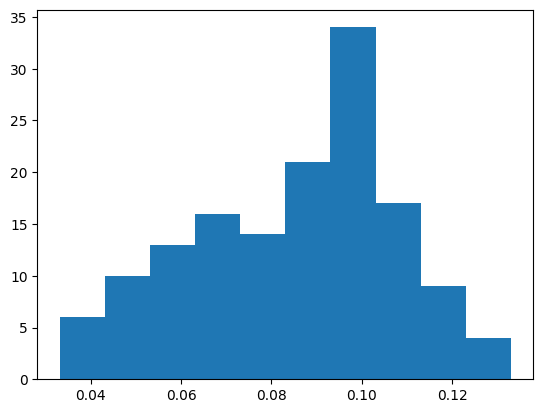

In [135]:
prs = []
for sample in loader:
    sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
    sample.X[:] = torch.asarray(X_scaler.transform(sample.X.numpy()))
    y = sample.y.to(device)
    X = sample.X.to(device)
    y_hat, z = model(X)
    pr = stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())[0]
    prs.append(pr)
    # break
plt.hist(prs)

In [136]:
prs = []
for sample in test_loader:
    sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
    sample.X[:] = torch.asarray(X_scaler.transform(sample.X.numpy()))
    y = sample.y.to(device)
    X = sample.X.to(device)
    y_hat, z = model(X)
    pr = stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())[0]
    prs.append(pr)
    # break

(array([3., 1., 6., 4., 4., 2., 8., 4., 3., 1.]),
 array([0.03233757, 0.04436563, 0.05639369, 0.06842176, 0.08044982,
        0.09247789, 0.10450595, 0.11653402, 0.12856208, 0.14059014,
        0.15261821]),
 <BarContainer object of 10 artists>)

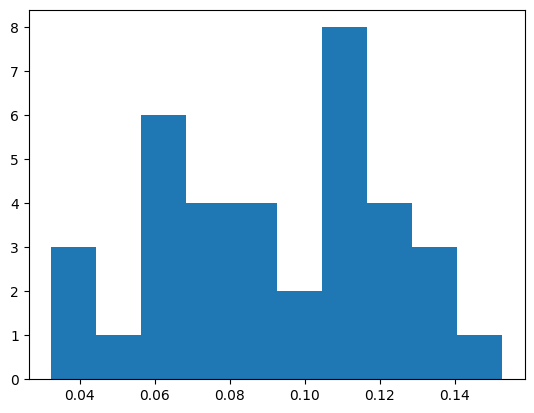

In [137]:
plt.hist(prs)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-2.59772539, -2.4925633 , -2.3874012 , -2.2822391 , -2.17707701,
        -2.07191491, -1.96675282, -1.86159072, -1.75642862, -1.65126653,
        -1.54610443, -1.44094234, -1.33578024, -1.23061814, -1.12545605,
        -1.02029395, -0.91513186, -0.80996976, -0.70480766, -0.59964557,
        -0.49448347, -0.38932137, -0.28415928, -0.17899718, -0.07383509,
         0.03132701,  0.13648911,  0.2416512 ,  0.3468133 ,  0.45197539,
         0.55713749,  0.66229959,  0.76746168,  0.87262378,  0.97778587,
         1.08294797,  1.18811007,  1.29327216,  1.39843426,  1.50359635,
         1.60875845,  1.71392055,  1.81908264,  1.92424474,  2.02940683,
         2.13456893,  2.23973103,  2.34489312,  2.45005522,  2.55521731,
         2.66037941])

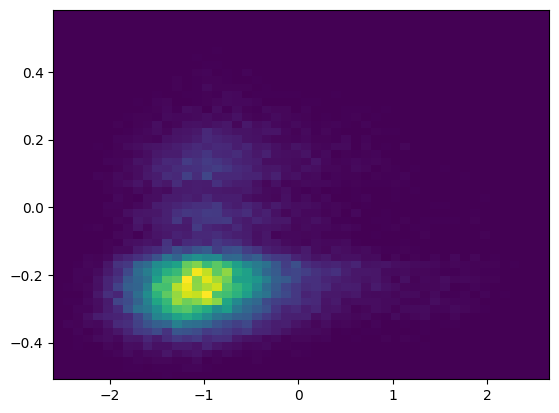

In [138]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_hat.detach().cpu().numpy().ravel(), bins=50)

In [139]:
import scipy.stats as stats

stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())

PearsonRResult(statistic=0.11974724414644103, pvalue=6.323776352322489e-105)